# Rocket Revolution: A Statistical Study of ISRO's Launch Activities (2005–2025)

**What this notebook does:** compiles ISRO's launch records for 2005–2025 into a structured dataset, then uses descriptive statistics, tables and graphs to study (1) how many launches ISRO made each year and (2) how often each launch vehicle was used.

**How to use it:** run **Kernel → Restart & Run All** (or *Run → Run All Cells*). Everything is self-contained: the dataset is inside the notebook, and running it also saves a CSV file, a `tables/` folder and a `figures/` folder next to the notebook. Needs: `pandas`, `numpy`, `matplotlib`, `scipy`.

**Data source:** ISRO *Launch Missions* table, <https://www.isro.gov.in/ISRO_EN/LaunchMissions.html> (serial nos. 20–104, i.e. every entry dated 1 Jan 2005 – 31 Dec 2025).

**Objectives**
1. Compile ISRO launch mission records for 2005–2025
2. Calculate the annual number of launches and examine changes over time
3. Compare the frequency of use of different launch vehicles
4. Present and interpret the main findings with tables and graphs

## 1. Setup

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 60)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

START, END = 2005, 2025
FAMILIES = ["PSLV", "GSLV (Mk II)", "LVM3 (ex GSLV Mk III)", "SSLV"]
COLORS = {"PSLV": "#1b6ca8", "GSLV (Mk II)": "#e08a1e", "LVM3 (ex GSLV Mk III)": "#2a9d5c", "SSLV": "#9b59b6"}

Path("figures").mkdir(exist_ok=True)
Path("tables").mkdir(exist_ok=True)

## 2. Data collection: the ISRO launch records

The 85 entries below were transcribed from ISRO's official Launch Missions table. Each row is
`(serial no., mission name as listed by ISRO, launch date, launcher-type cell, headline payload, ISRO remark)`.

> ISRO's table also has older entries (1979–2004) and entries dated 2026; both are outside the study period and left out.

In [2]:
DATA = [
    (20, "PSLV-C6 / CARTOSAT-1 / HAMSAT", "2005-05-05", "PSLV-G", "CARTOSAT-1, HAMSAT", ""),
    (21, "GSLV-F02 / INSAT-4C", "2006-07-10", "GSLV-MK-II", "INSAT-4C", "Mission Unsuccessful"),
    (22, "PSLV-C7 / CARTOSAT-2 / SRE-1", "2007-01-10", "PSLV-G", "CARTOSAT-2, SRE-1", ""),
    (23, "PSLV-C8 / AGILE", "2007-04-23", "PSLV-CA", "AGILE", ""),
    (24, "GSLV-F04 / INSAT-4CR", "2007-09-02", "GSLV-MK-II", "INSAT-4CR", ""),
    (25, "PSLV-C10 / TECSAR", "2008-01-21", "PSLV-CA", "TECSAR", ""),
    (26, "PSLV-C9 / CARTOSAT-2A", "2008-04-28", "PSLV-CA", "CARTOSAT-2A, IMS-1", ""),
    (27, "PSLV-C11 / Chandrayaan-1", "2008-10-22", "PSLV-XL", "Chandrayaan-1", ""),
    (28, "PSLV-C12 / RISAT-2", "2009-04-20", "PSLV-CA", "RISAT-2", ""),
    (29, "PSLV-C14 / OCEANSAT-2", "2009-09-23", "PSLV-CA", "Oceansat-2", ""),
    (30, "GSLV-D3 / GSAT-4", "2010-04-15", "GSLV-MK-II", "GSAT-4", "Mission Unsuccessful"),
    (31, "PSLV-C15 / CARTOSAT-2B", "2010-07-12", "PSLV-CA", "CARTOSAT-2B", ""),
    (32, "GSLV-F06 / GSAT-5P", "2010-12-25", "GSLV-MK-II", "GSAT-5P", "Mission Unsuccessful"),
    (33, "PSLV-C16 / RESOURCESAT-2", "2011-04-20", "PSLV-G", "RESOURCESAT-2, YOUTHSAT", ""),
    (34, "PSLV-C17 / GSAT-12", "2011-07-15", "PSLV-XL", "GSAT-12", ""),
    (35, "PSLV-C18 / Megha-Tropiques", "2011-10-12", "PSLV-CA", "Megha-Tropiques", ""),
    (36, "PSLV-C19 / RISAT-1", "2012-04-26", "PSLV-XL", "RISAT-1", ""),
    (37, "PSLV-C21 / SPOT-6", "2012-09-09", "PSLV-CA", "SPOT-6", ""),
    (38, "PSLV-C20 / SARAL", "2013-02-25", "PSLV-CA", "SARAL", ""),
    (39, "PSLV-C22 / IRNSS-1A", "2013-07-01", "PSLV-XL", "IRNSS-1A", ""),
    (40, "PSLV-C25 / Mars Orbiter Mission", "2013-11-05", "PSLV-XL", "Mars Orbiter Mission", ""),
    (41, "GSLV-D5 / GSAT-14", "2014-01-05", "GSLV-MK-II", "GSAT-14", ""),
    (42, "PSLV-C24 / IRNSS-1B", "2014-04-04", "PSLV-XL", "IRNSS-1B", ""),
    (43, "PSLV-C23 / SPOT-7", "2014-06-30", "PSLV-CA", "SPOT-7", ""),
    (44, "PSLV-C26 / IRNSS-1C", "2014-10-16", "PSLV-XL", "IRNSS-1C", ""),
    (45, "LVM-3 / CARE", "2014-12-18", "GSLV-MK-III", "Crew module Atmospheric Re-entry Experiment (CARE)", ""),
    (46, "PSLV-C27 / IRNSS-1D", "2015-03-28", "PSLV-XL", "IRNSS-1D", ""),
    (47, "PSLV-C28 / DMC3", "2015-07-10", "PSLV-XL", "DMC3", ""),
    (48, "GSLV-D6 / GSAT-6", "2015-08-27", "GSLV-MK-II", "GSAT-6", ""),
    (49, "PSLV-C30 / AstroSat", "2015-09-28", "PSLV-XL", "AstroSat", ""),
    (50, "PSLV-C29 / TeLEOS-1", "2015-12-16", "PSLV-CA", "TeLEOS-1", ""),
    (51, "PSLV-C31 / IRNSS-1E", "2016-01-20", "PSLV-XL", "IRNSS-1E", ""),
    (52, "PSLV-C32 / IRNSS-1F", "2016-03-10", "PSLV-XL", "IRNSS-1F", ""),
    (53, "PSLV-C33 / IRNSS-1G", "2016-04-28", "PSLV-XL", "IRNSS-1G", ""),
    (54, "RLV-TD HEX", "2016-05-23", "", "RLV-TD", ""),
    (55, "PSLV-C34 / CARTOSAT-2 Series Satellite", "2016-06-22", "PSLV-XL", "CARTOSAT-2 Series", ""),
    (56, "Scramjet Engine - TD", "2016-08-28", "", "Scramjet Engine technology demonstrator", ""),
    (57, "GSLV-F05 / INSAT-3DR", "2016-09-08", "GSLV-MK-II", "INSAT-3DR", ""),
    (58, "PSLV-C35 / SCATSAT-1", "2016-09-26", "PSLV", "SCATSAT-1", ""),
    (59, "PSLV-C36 / RESOURCESAT-2A", "2016-12-07", "PSLV-XL", "RESOURCESAT-2A", ""),
    (60, "PSLV-C37 / Cartosat-2 Series Satellite", "2017-02-15", "PSLV-XL", "Cartosat-2 Series", ""),
    (61, "GSLV-F09 / GSAT-9", "2017-05-05", "GSLV", "GSAT-9", ""),
    (62, "GSLV Mk III-D1 / GSAT-19", "2017-06-05", "GSLV-MK-III", "GSAT-19", ""),
    (63, "PSLV-C38 / Cartosat-2 Series Satellite", "2017-06-23", "PSLV-XL", "Cartosat-2 Series", ""),
    (64, "PSLV-C39 / IRNSS-1H", "2017-08-31", "PSLV-XL", "IRNSS-1H", "Mission Unsuccessful"),
    (65, "PSLV-C40 / Cartosat-2 Series Satellite", "2018-01-12", "PSLV-XL", "Cartosat-2 Series", ""),
    (66, "GSLV-F08 / GSAT-6A", "2018-03-29", "GSLV", "GSAT-6A", ""),
    (67, "PSLV-C41 / IRNSS-1I", "2018-04-12", "PSLV-XL", "IRNSS-1I", ""),
    (68, "PAT: Crew Escape System", "2018-07-05", "", "Crew Escape System (Pad Abort Test)", ""),
    (69, "PSLV-C42 / NOVASAR", "2018-09-16", "PSLV", "NOVASAR", ""),
    (70, "GSLV Mk III-D2 / GSAT-29", "2018-11-14", "GSLV-MK-III", "GSAT-29", ""),
    (71, "PSLV-C43 / HysIS", "2018-11-29", "PSLV", "HysIS", ""),
    (72, "GSLV-F11 / GSAT-7A", "2018-12-19", "GSLV", "GSAT-7A", ""),
    (73, "PSLV-C44 / Microsat-R", "2019-01-24", "PSLV-DL", "Microsat-R", ""),
    (74, "PSLV-C45 / EMISAT", "2019-04-01", "PSLV-QL", "EMISAT", ""),
    (75, "PSLV-C46 / RISAT-2B", "2019-05-22", "PSLV-CA", "RISAT-2B", ""),
    (76, "GSLV-Mk III-M1 / Chandrayaan-2", "2019-07-22", "GSLV-MK-III", "Chandrayaan-2", ""),
    (77, "PSLV-C47 / Cartosat-3", "2019-11-27", "PSLV-XL", "Cartosat-3", ""),
    (78, "PSLV-C48 / RISAT-2BR1", "2019-12-11", "PSLV-QL", "RISAT-2BR1", ""),
    (79, "PSLV-C49 / EOS-01", "2020-11-07", "PSLV-DL", "EOS-01", ""),
    (80, "PSLV-C50 / CMS-01", "2020-12-17", "PSLV-XL", "CMS-01", ""),
    (81, "PSLV-C51 / Amazonia-1", "2021-02-28", "PSLV-DL", "Amazonia-1", ""),
    (82, "GSLV-F10 / EOS-03", "2021-08-12", "GSLV", "EOS-03", "Mission unsuccessful"),
    (83, "PSLV-C52 / EOS-04", "2022-02-14", "PSLV-XL", "EOS-04", ""),
    (84, "PSLV-C53 / DS-EO", "2022-06-30", "", "DS-EO", ""),
    (85, "SSLV-D1 / EOS-D2", "2022-08-07", "SSLV", "EOS-02 (listed as EOS-D2)", ""),
    (86, "LVM3 M2 / OneWeb India-1", "2022-10-23", "LVM3", "OneWeb Gen-1", ""),
    (87, "PSLV-C54 / EOS-06", "2022-11-26", "PSLV-XL", "EOS-06", ""),
    (88, "SSLV-D2 / EOS-07", "2023-02-10", "SSLV", "EOS-07", ""),
    (89, "LVM3 M3 / OneWeb India-2", "2023-03-26", "LVM3", "OneWeb Gen-1", ""),
    (90, "PSLV-C55 / TeLEOS-2", "2023-04-22", "PSLV-CA", "TeLEOS-2", ""),
    (91, "GSLV-F12 / NVS-01", "2023-05-29", "GSLV", "NVS-01", ""),
    (92, "LVM3 M4 / Chandrayaan-3", "2023-07-14", "LVM3", "Chandrayaan-3", ""),
    (93, "PSLV-C56 / DS-SAR", "2023-07-30", "PSLV-CA", "DS-SAR", ""),
    (94, "PSLV-C57 / Aditya-L1", "2023-09-02", "PSLV-XL", "Aditya-L1", ""),
    (95, "PSLV-C58 / XPoSat", "2024-01-01", "PSLV-DL", "XPoSat", ""),
    (96, "GSLV-F14 / INSAT-3DS", "2024-02-17", "GSLV", "INSAT-3DS", ""),
    (97, "SSLV-D3 / EOS-08", "2024-08-16", "SSLV", "EOS-08", ""),
    (98, "PSLV-C59 / Proba-3", "2024-12-05", "PSLV", "Proba-3", ""),
    (99, "PSLV-C60 / SPADEX", "2024-12-30", "PSLV", "SPADEX-A, SPADEX-B, POEM-4", ""),
    (100, "GSLV-F15 / NVS-02", "2025-01-29", "GSLV", "NVS-02", ""),
    (101, "PSLV-C61 / EOS-09", "2025-05-18", "PSLV", "EOS-09", "Not accomplished"),
    (102, "GSLV-F16 / NISAR", "2025-07-30", "GSLV", "NISAR", ""),
    (103, "LVM3-M5 / CMS-03", "2025-11-02", "LVM3", "CMS-03", ""),
    (104, "LVM3-M6 / Blue Bird Block2", "2025-12-24", "LVM3", "Blue Bird Block 2", ""),
]

## 3. Organising the data into a structured dataset

New columns are derived from ISRO's entries:

| Column | How it is built |
|---|---|
| `year`, `month` | from the launch date |
| `vehicle_family` | **PSLV**, **GSLV (Mk II)**, **LVM3** or **SSLV**, taken from the mission name. ISRO renamed *GSLV Mk III* to *LVM3*, so both names are merged |
| `category` | Orbital launch / Suborbital test (CARE) / Technology demonstration |
| `outcome` | **Failure** if ISRO's remark says *unsuccessful* / *not accomplished* (6 missions), plus **SSLV-D1** (7 Aug 2022), which ISRO's table doesn't flag but ISRO itself announced as a failure (satellites left in a 356 × 76 km orbit and "no longer usable"). Everything else is **Success** |

**What counts as a "launch"?** ISRO's table includes three entries with no launcher type: the reusable-launch-vehicle demonstrator (RLV-TD, May 2016), the Scramjet engine demonstrator (Aug 2016) and the Pad Abort Test (Jul 2018). These are technology tests rather than flights of a launch vehicle, so they stay in the dataset but are **not counted as launches**. The LVM3 **CARE** flight (Dec 2014) is a suborbital experimental flight of an LVM3 vehicle, so it **is counted** but flagged. Section 9 shows the results don't depend on these choices.

In [3]:
FAIL_REMARK = "unsuccessful|not accomplished"


def family(mission):
    m = mission.upper()
    if m.startswith("PSLV"):
        return "PSLV"
    if m.startswith("SSLV"):
        return "SSLV"
    if m.startswith("LVM") or "MK III" in m or "MK-III" in m:
        return "LVM3 (ex GSLV Mk III)"
    if m.startswith("GSLV"):
        return "GSLV (Mk II)"
    return "Technology demonstration"


df = pd.DataFrame(DATA, columns=["sl_no", "mission", "launch_date", "isro_launcher_type", "payload", "isro_remark"])
df["launch_date"] = pd.to_datetime(df["launch_date"])
df["year"] = df.launch_date.dt.year
df["month"] = df.launch_date.dt.month
df["vehicle_family"] = df.mission.map(family)
df["category"] = np.where(df.vehicle_family == "Technology demonstration", "Technology demonstration",
                 np.where(df.mission.str.contains("CARE"), "Suborbital test (CARE)", "Orbital launch"))
is_fail = df.isro_remark.str.lower().str.contains(FAIL_REMARK) | df.mission.str.startswith("SSLV-D1")
df["outcome"] = np.where(df.category == "Technology demonstration", "n/a", np.where(is_fail, "Failure", "Success"))

assert df.year.between(START, END).all() and len(df) == 85
df.to_csv("isro_launches_2005_2025.csv", index=False, date_format="%Y-%m-%d")
print(f"Dataset: {len(df)} entries, saved to isro_launches_2005_2025.csv")
df[["sl_no", "launch_date", "mission", "vehicle_family", "category", "outcome"]].head(12)

Dataset: 85 entries, saved to isro_launches_2005_2025.csv


,sl_no,launch_date,mission,vehicle_family,category,outcome
0,20,2005-05-05,PSLV-C6 / CARTOSAT-1 / HAMSAT,PSLV,Orbital launch,Success
1,21,2006-07-10,GSLV-F02 / INSAT-4C,GSLV (Mk II),Orbital launch,Failure
2,22,2007-01-10,PSLV-C7 / CARTOSAT-2 / SRE-1,PSLV,Orbital launch,Success
3,23,2007-04-23,PSLV-C8 / AGILE,PSLV,Orbital launch,Success
4,24,2007-09-02,GSLV-F04 / INSAT-4CR,GSLV (Mk II),Orbital launch,Success
5,25,2008-01-21,PSLV-C10 / TECSAR,PSLV,Orbital launch,Success
6,26,2008-04-28,PSLV-C9 / CARTOSAT-2A,PSLV,Orbital launch,Success
7,27,2008-10-22,PSLV-C11 / Chandrayaan-1,PSLV,Orbital launch,Success
8,28,2009-04-20,PSLV-C12 / RISAT-2,PSLV,Orbital launch,Success
9,29,2009-09-23,PSLV-C14 / OCEANSAT-2,PSLV,Orbital launch,Success


In [4]:
# the analysis population: flights of ISRO launch vehicles (technology demonstrations excluded)
launches = df[df.category != "Technology demonstration"].copy()
print("Entries in dataset:", len(df), "| launches analysed:", len(launches))
df.category.value_counts().to_frame("entries")

Entries in dataset: 85 | launches analysed: 82


,entries
category,
Orbital launch,81
Technology demonstration,3
Suborbital test (CARE),1


## 4. Annual number of launches (Objective 2)
Launches per year, with every year from 2005 to 2025 included (a year with no launch would show as 0; there are none).

In [5]:
annual = launches.groupby("year").size().reindex(range(START, END + 1), fill_value=0)
annual_table = pd.DataFrame({"launches": annual,
                             "3yr_moving_avg": annual.rolling(3, center=True).mean().round(2),
                             "cumulative": annual.cumsum(),
                             "change_vs_prev_year": annual.diff()})
annual_table.to_csv("tables/annual_launches.csv")
annual_table

,launches,3yr_moving_avg,cumulative,change_vs_prev_year
year,,,,
2005,1,NaN,1,NaN
2006,1,1.67,2,0.0
2007,3,2.33,5,2.0
2008,3,2.67,8,0.0
2009,2,2.67,10,-1.0
2010,3,2.67,13,1.0
2011,3,2.67,16,0.0
2012,2,2.67,18,-1.0
2013,3,3.33,21,1.0


In [6]:
desc = pd.Series({
    "Years observed": len(annual),
    "Total launches": int(annual.sum()),
    "Mean per year": round(annual.mean(), 2),
    "Median per year": annual.median(),
    "Standard deviation": round(annual.std(ddof=1), 2),
    "Minimum": int(annual.min()),
    "Maximum": int(annual.max()),
    "Lower quartile (Q1)": annual.quantile(.25),
    "Upper quartile (Q3)": annual.quantile(.75),
    "Most frequent annual count (mode)": int(annual.mode().iloc[0]),
}, name="value").to_frame()
print("Years with the minimum count:", list(annual[annual == annual.min()].index))
print("Years with the maximum count:", list(annual[annual == annual.max()].index))
desc

Years with the minimum count: [2005, 2006]
Years with the maximum count: [2016, 2018, 2023]


,value
Years observed,21.00
Total launches,82.00
Mean per year,3.90
Median per year,3.00
Standard deviation,1.95
Minimum,1.00
Maximum,7.00
Lower quartile (Q1),2.00
Upper quartile (Q3),5.00
Most frequent annual count (mode),5.00


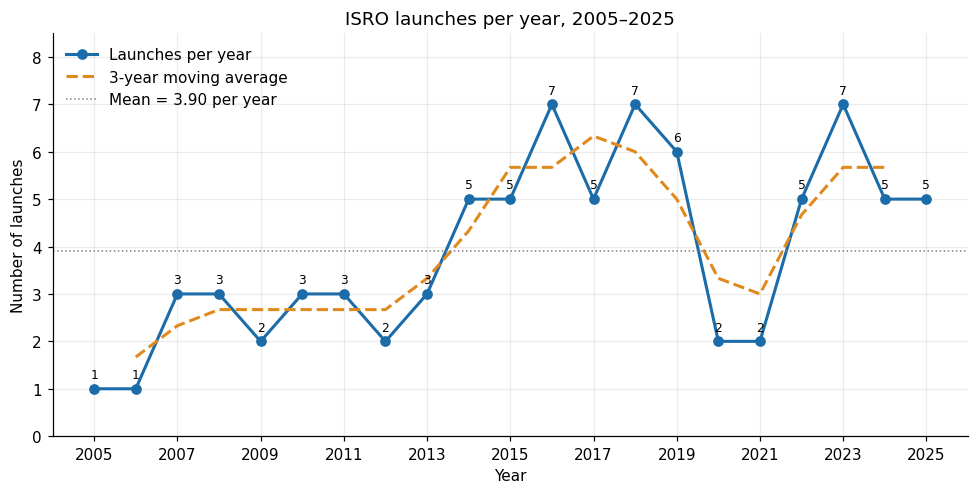

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(annual.index, annual.values, marker="o", color="#1b6ca8", lw=2, label="Launches per year")
ax.plot(annual_table.index, annual_table["3yr_moving_avg"], color="#e08a1e", lw=2, ls="--", label="3-year moving average")
ax.axhline(annual.mean(), color="grey", lw=1, ls=":", label=f"Mean = {annual.mean():.2f} per year")
for y, v in annual.items():
    ax.annotate(int(v), (y, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(xlabel="Year", ylabel="Number of launches", title="ISRO launches per year, 2005–2025", ylim=(0, annual.max() + 1.5))
ax.set_xticks(range(START, END + 1, 2))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("figures/fig1_launches_per_year.png", dpi=200)
plt.show()

**Reading Figure 1.** Activity started small, with a single launch in each of 2005 and 2006, reached 3 a year by 2007 and then stayed at 2–3 launches a year until 2013. It stepped up to 5 in 2014 and 2015, and the record of **7 launches** was reached in **2016, 2018 and 2023**. After 6 launches in 2019 the count dropped to **2 in both 2020 and 2021**, then recovered to 5, 7, 5 and 5 in 2022–2025.

## 5. Changes over time (Objective 2)

Three simple checks of whether launch activity changed:
1. **Two periods compared**, 2005–2014 (10 years) vs 2015–2025 (11 years), using the **Mann–Whitney U test** (suited to small integer counts that aren't normally distributed).
2. A **straight-line trend** (ordinary least squares) of launches on year, with a 95% confidence interval for the slope.
3. **Kendall's tau**, a rank correlation between year and launches that doesn't assume a straight line.

With only 21 yearly observations, treat these as supporting evidence rather than proof.

In [8]:
p1, p2 = annual.loc[2005:2014], annual.loc[2015:2025]
periods = pd.DataFrame({
    "years": [len(p1), len(p2), len(annual)],
    "launches": [p1.sum(), p2.sum(), annual.sum()],
    "mean_per_year": [p1.mean(), p2.mean(), annual.mean()],
    "median_per_year": [p1.median(), p2.median(), annual.median()],
    "std_dev": [p1.std(ddof=1), p2.std(ddof=1), annual.std(ddof=1)],
    "min": [p1.min(), p2.min(), annual.min()],
    "max": [p1.max(), p2.max(), annual.max()],
}, index=["2005–2014", "2015–2025", "2005–2025"]).round(2)
display(periods)

mw = stats.mannwhitneyu(p1, p2, alternative="two-sided")
print(f"Ratio of mean launches per year (2015–2025 / 2005–2014): {p2.mean() / p1.mean():.2f}")
print(f"Mann–Whitney U = {mw.statistic:.1f}, two-sided p-value = {mw.pvalue:.4f}")

,years,launches,mean_per_year,median_per_year,std_dev,min,max
2005–2014,10,26,2.60,3.0,1.17,1,5
2015–2025,11,56,5.09,5.0,1.76,2,7
2005–2025,21,82,3.90,3.0,1.95,1,7


Ratio of mean launches per year (2015–2025 / 2005–2014): 1.96
Mann–Whitney U = 16.5, two-sided p-value = 0.0062


In [9]:
def trend(counts):
    x, y = counts.index.values.astype(float), counts.values.astype(float)
    r = stats.linregress(x, y)
    t = stats.t.ppf(0.975, len(x) - 2)
    tau, p_tau = stats.kendalltau(x, y)
    return pd.Series({"slope (launches/yr per yr)": r.slope,
                      "95% CI low": r.slope - t * r.stderr, "95% CI high": r.slope + t * r.stderr,
                      "p-value (slope)": r.pvalue, "R²": r.rvalue ** 2,
                      "Kendall tau": tau, "p-value (tau)": p_tau})

trend_table = pd.DataFrame({"all years 2005–2025": trend(annual), "2005–2019 only": trend(annual.loc[2005:2019])}).round(3)
trend_table

,all years 2005–2025,2005–2019 only
slope (launches/yr per yr),0.195,0.393
95% CI low,0.077,0.270
95% CI high,0.313,0.515
p-value (slope),0.003,0.000
R²,0.385,0.787
Kendall tau,0.475,0.734
p-value (tau),0.005,0.000


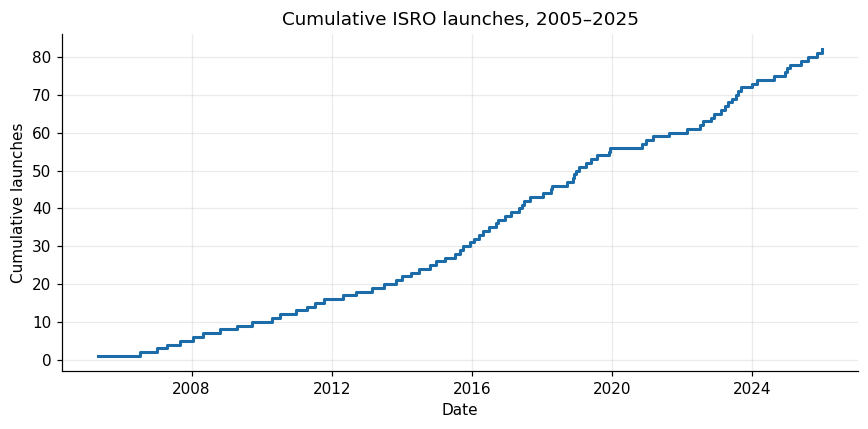

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
d = launches.sort_values("launch_date")
ax.step(d.launch_date, np.arange(1, len(d) + 1), where="post", color="#1b6ca8", lw=2)
ax.set(xlabel="Date", ylabel="Cumulative launches", title="Cumulative ISRO launches, 2005–2025")
fig.tight_layout()
fig.savefig("figures/fig4_cumulative.png", dpi=200)
plt.show()

**Interpretation.** ISRO made **26 launches in 2005–2014 (2.6 a year)** and **56 in 2015–2025 (5.1 a year)**, about twice as many, and the difference is statistically significant. The fitted line rises by roughly **0.2 launches per year**, and Kendall's tau is positive and significant, so the upward movement shows up whichever method is used.

Two cautions. First, the 2020–2021 dip pulls the all-years slope down; using only 2005–2019 the slope is steeper (right-hand column). That second line is a *post-hoc* comparison, shown only to illustrate the dip's effect. Second, since the recovery launches have levelled off at about five a year, so a straight line is only a rough description of the whole period. The dip coincides with the COVID-19 pandemic (and 2021 includes the failed GSLV-F10 launch), but annual counts alone cannot prove the cause.

## 6. Launch-vehicle usage (Objective 3)
How often was each launch vehicle used? Percentages are shares of the 82 launches.

In [11]:
vc = launches.vehicle_family.value_counts().reindex(FAMILIES)
vehicle = pd.DataFrame({"launches": vc, "share_%": (100 * vc / vc.sum()).round(1)})
vehicle["first_launch"] = launches.groupby("vehicle_family").launch_date.min().reindex(FAMILIES).dt.date
vehicle["latest_launch"] = launches.groupby("vehicle_family").launch_date.max().reindex(FAMILIES).dt.date
vehicle["years_used"] = launches.groupby("vehicle_family").year.nunique().reindex(FAMILIES)
vehicle.loc["Total"] = [vc.sum(), 100.0, "", "", ""]
vehicle.to_csv("tables/vehicle_usage.csv")
vehicle

,launches,share_%,first_launch,latest_launch,years_used
vehicle_family,,,,,
PSLV,55,67.1,2005-05-05,2025-05-18,20
GSLV (Mk II),15,18.3,2006-07-10,2025-07-30,12
LVM3 (ex GSLV Mk III),9,11.0,2014-12-18,2025-12-24,7
SSLV,3,3.7,2022-08-07,2024-08-16,3
Total,82,100.0,,,


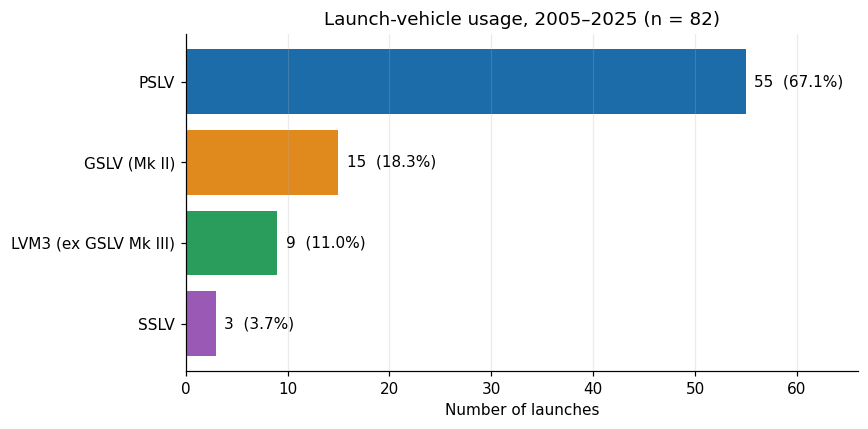

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
v = vc.iloc[::-1]
bars = ax.barh(v.index, v.values, color=[COLORS[x] for x in v.index])
for b, n in zip(bars, v.values):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"{n}  ({100 * n / vc.sum():.1f}%)", va="center")
ax.set(xlabel="Number of launches", title="Launch-vehicle usage, 2005–2025 (n = 82)", xlim=(0, v.max() * 1.2))
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/fig2_vehicle_usage.png", dpi=200)
plt.show()

**Reading Figure 2.** The **PSLV** dominates with 55 launches (67.1%) and was flown in 20 of the 21 years (every year except 2006). The **GSLV Mk II** flew 15 times (18.3%), the **LVM3** 9 times (11.0%, starting with the CARE test flight in December 2014) and the small-satellite **SSLV** 3 times (3.7%, between August 2022 and August 2024).

In [13]:
by_year = pd.crosstab(launches.year, launches.vehicle_family).reindex(index=range(START, END + 1), columns=FAMILIES, fill_value=0)
by_year["Total"] = by_year.sum(axis=1)
by_year.to_csv("tables/launches_by_year_and_vehicle.csv")
by_year

vehicle_family,PSLV,GSLV (Mk II),LVM3 (ex GSLV Mk III),SSLV,Total
year,,,,,
2005,1,0,0,0,1
2006,0,1,0,0,1
2007,2,1,0,0,3
2008,3,0,0,0,3
2009,2,0,0,0,2
2010,1,2,0,0,3
2011,3,0,0,0,3
2012,2,0,0,0,2
2013,3,0,0,0,3


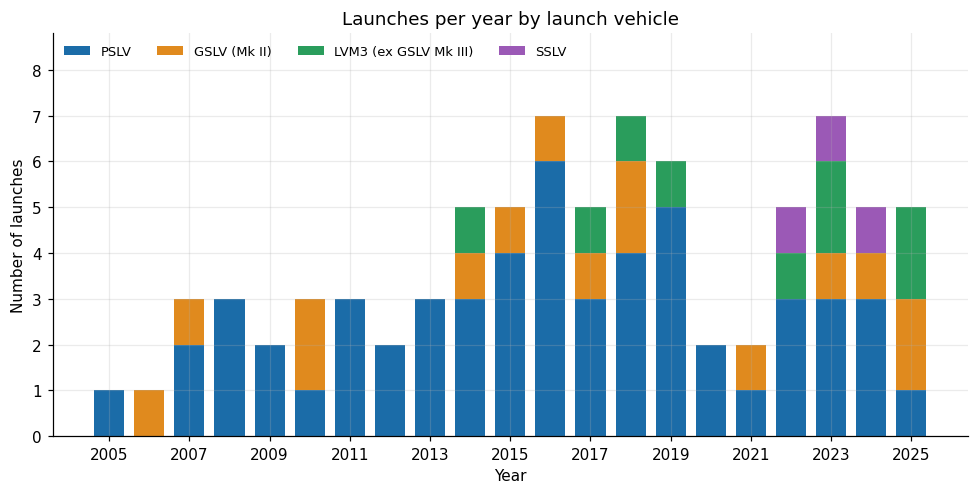

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.6))
bottom = np.zeros(len(by_year))
for fam in FAMILIES:
    ax.bar(by_year.index, by_year[fam], bottom=bottom, color=COLORS[fam], label=fam, width=0.75)
    bottom += by_year[fam].values
ax.set(xlabel="Year", ylabel="Number of launches", title="Launches per year by launch vehicle", ylim=(0, annual.max() + 1.8))
ax.set_xticks(range(START, END + 1, 2))
ax.legend(frameon=False, ncol=4, loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig("figures/fig3_year_by_vehicle.png", dpi=200)
plt.show()

In [15]:
period = np.where(launches.year <= 2014, "2005–2014", "2015–2025")
pv = pd.crosstab(launches.vehicle_family, period).reindex(FAMILIES)
pv.loc["Total"] = pv.sum()
pv["2005–2014 per year"] = (pv["2005–2014"] / 10).round(2)
pv["2015–2025 per year"] = (pv["2015–2025"] / 11).round(2)
print(f"PSLV share of launches: 2005–2014 = {100 * pv.loc['PSLV', '2005–2014'] / pv.loc['Total', '2005–2014']:.1f}%, "
      f"2015–2025 = {100 * pv.loc['PSLV', '2015–2025'] / pv.loc['Total', '2015–2025']:.1f}%")
pv

PSLV share of launches: 2005–2014 = 76.9%, 2015–2025 = 62.5%


col_0,2005–2014,2015–2025,2005–2014 per year,2015–2025 per year
vehicle_family,,,,
PSLV,20,35,2.0,3.18
GSLV (Mk II),5,10,0.5,0.91
LVM3 (ex GSLV Mk III),1,8,0.1,0.73
SSLV,0,3,0.0,0.27
Total,26,56,2.6,5.09


**Interpretation.** The vehicle mix changed between the two periods. PSLV's share fell from **76.9%** (20 of 26) to **62.5%** (35 of 56) even though the number of PSLV launches per year went *up* (2.0 to 3.2). So the rise in total launches came both from more PSLV flights **and** from newer vehicles: LVM3 went from 1 flight to 8, SSLV from none to 3, and GSLV Mk II from 5 to 10.

ISRO's table also names PSLV configurations (the most common being PSLV-XL), but for some launches it gives only "PSLV" or leaves the cell blank, so this study works at the level of vehicle family.

## 7. Launch outcomes (extra)
Success rates, with **Wilson 95% confidence intervals** (appropriate for proportions based on small numbers of launches).

In [16]:
def wilson(k, n, z=1.96):
    p, d = k / n, 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return 100 * (c - h), 100 * (c + h)

rows = []
for fam in FAMILIES + ["All vehicles"]:
    sub = launches if fam == "All vehicles" else launches[launches.vehicle_family == fam]
    n, f = len(sub), int((sub.outcome == "Failure").sum())
    lo, hi = wilson(n - f, n)
    rows.append({"vehicle": fam, "launches": n, "successes": n - f, "failures": f,
                 "success_rate_%": round(100 * (n - f) / n, 1), "95% CI low": round(lo, 1), "95% CI high": round(hi, 1)})
outcomes = pd.DataFrame(rows).set_index("vehicle")
outcomes.to_csv("tables/outcomes_by_vehicle.csv")
display(outcomes)
print("\nFailures:")
launches[launches.outcome == "Failure"][["launch_date", "mission", "isro_remark"]].assign(launch_date=lambda x: x.launch_date.dt.date)

,launches,successes,failures,success_rate_%,95% CI low,95% CI high
vehicle,,,,,,
PSLV,55,53,2,96.4,87.7,99.0
GSLV (Mk II),15,11,4,73.3,48.0,89.1
LVM3 (ex GSLV Mk III),9,9,0,100.0,70.1,100.0
SSLV,3,2,1,66.7,20.8,93.9
All vehicles,82,75,7,91.5,83.4,95.8



Failures:


,launch_date,mission,isro_remark
1,2006-07-10,GSLV-F02 / INSAT-4C,Mission Unsuccessful
10,2010-04-15,GSLV-D3 / GSAT-4,Mission Unsuccessful
12,2010-12-25,GSLV-F06 / GSAT-5P,Mission Unsuccessful
44,2017-08-31,PSLV-C39 / IRNSS-1H,Mission Unsuccessful
62,2021-08-12,GSLV-F10 / EOS-03,Mission unsuccessful
65,2022-08-07,SSLV-D1 / EOS-D2,
81,2025-05-18,PSLV-C61 / EOS-09,Not accomplished


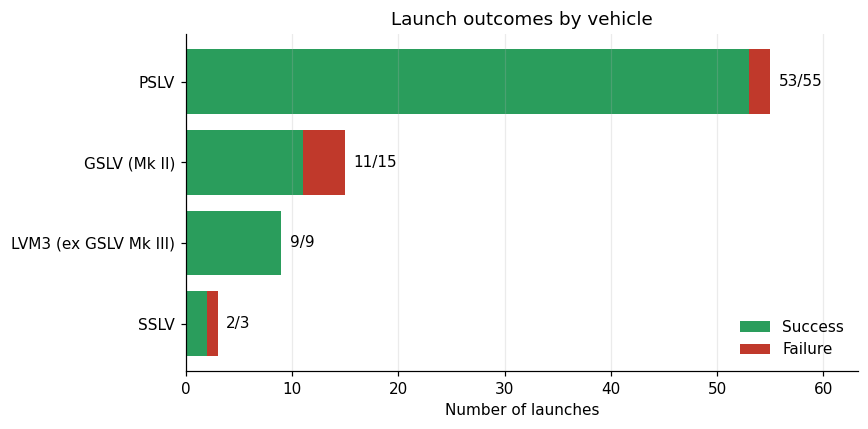

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
o = outcomes.drop("All vehicles").iloc[::-1]
ax.barh(o.index, o.successes, color="#2a9d5c", label="Success")
ax.barh(o.index, o.failures, left=o.successes, color="#c0392b", label="Failure")
for i, (s, f) in enumerate(zip(o.successes, o.failures)):
    ax.text(s + f + 0.8, i, f"{s}/{s + f}", va="center")
ax.set(xlabel="Number of launches", title="Launch outcomes by vehicle", xlim=(0, o.launches.max() * 1.15))
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/fig5_outcomes.png", dpi=200)
plt.show()

**Interpretation.** 75 of 82 launches (91.5%) succeeded. PSLV succeeded in 53 of 55 (96.4%); GSLV Mk II had four failures in 15 launches (2006, two in 2010, 2021) but its four launches in 2023–2025 all succeeded; LVM3 has succeeded in all 9 flights and SSLV in 2 of 3. Because LVM3 and SSLV have flown so few times, their confidence intervals are wide: a perfect record on 9 flights is not strong proof of a lower failure rate.

*"Success" here means only that the launch was not flagged as a failure; later problems with a spacecraft aren't captured.*

## 8. Launch cadence: time between consecutive launches (extra)

In [18]:
d = launches.sort_values("launch_date").reset_index(drop=True)
d["gap_days"] = d.launch_date.diff().dt.days
g = d.gap_days.dropna()
print(f"Gaps between consecutive launches (n = {len(g)}): mean {g.mean():.0f} days, median {g.median():.0f}, "
      f"SD {g.std(ddof=1):.0f}, min {g.min():.0f}, max {g.max():.0f}")
for lab, m in [("launches in 2005–2014", d.year <= 2014), ("launches in 2015–2025", d.year >= 2015)]:
    s = d[m].gap_days.dropna()
    print(f"  {lab}: mean gap {s.mean():.0f} days, median {s.median():.0f}")
print("\nFive longest gaps:")
d.nlargest(5, "gap_days")[["launch_date", "mission", "gap_days"]].assign(launch_date=lambda x: x.launch_date.dt.date)

Gaps between consecutive launches (n = 81): mean 93 days, median 77, SD 69, min 14, max 431
  launches in 2005–2014: mean gap 141 days, median 127
  launches in 2015–2025: mean gap 72 days, median 57

Five longest gaps:


,launch_date,mission,gap_days
1,2006-07-10,GSLV-F02 / INSAT-4C,431.0
56,2020-11-07,PSLV-C49 / EOS-01,332.0
10,2010-04-15,GSLV-D3 / GSAT-4,204.0
16,2012-04-26,PSLV-C19 / RISAT-1,197.0
60,2022-02-14,PSLV-C52 / EOS-04,186.0


The average gap between launches shrank from about 141 days (roughly 4.5 months) in 2005–2014 to about 72 days (roughly 2.5 months) in 2015–2025, the same change seen in the annual counts. The longest gaps were 431 days (PSLV-C6 in May 2005 to GSLV-F02 in July 2006) and 332 days (PSLV-C48 in Dec 2019 to PSLV-C49 in Nov 2020).

## 9. Do the conclusions depend on what we call a "launch"? (sensitivity check)
The main results use 82 launches. Here the headline numbers are repeated using (a) all 85 entries including the three technology demonstrations and (b) only the 81 orbital attempts (CARE excluded).

In [19]:
def annual_counts(d):
    return d.groupby("year").size().reindex(range(START, END + 1), fill_value=0)

defs = {"82 launches (main analysis)": launches,
        "85 entries incl. 3 tech demonstrations": df,
        "81 orbital attempts (CARE excluded)": launches[launches.category == "Orbital launch"]}
rows = {}
for name, dd in defs.items():
    a_ = annual_counts(dd)
    r = stats.linregress(a_.index.values.astype(float), a_.values.astype(float))
    rows[name] = {"total": int(a_.sum()), "mean/yr (all)": a_.mean(), "mean/yr 2005–14": a_.loc[2005:2014].mean(),
                  "mean/yr 2015–25": a_.loc[2015:2025].mean(), "trend slope/yr": r.slope, "slope p-value": r.pvalue}
pd.DataFrame(rows).T.round(3)

,total,mean/yr (all),mean/yr 2005–14,mean/yr 2015–25,trend slope/yr,slope p-value
82 launches (main analysis),82.0,3.905,2.6,5.091,0.195,0.003
85 entries incl. 3 tech demonstrations,85.0,4.048,2.6,5.364,0.201,0.008
81 orbital attempts (CARE excluded),81.0,3.857,2.5,5.091,0.196,0.002


The conclusions (roughly double the launch rate after 2014, and a positive, significant trend) hold under all three definitions.

## 10. Discussion
- **Launch activity has grown, but not steadily.** The clearest pattern is a step change around 2014–2015: ISRO flew two to three times a year in the first decade and typically five or more after. The period comparison, the regression slope, the rank correlation and the shorter gaps between launches all agree. The 2020–2021 dip interrupted the climb, and the post-pandemic level (about 5 a year) sits below the 2016, 2018 and 2019 peaks, although 2023 matched them.
- **The PSLV is the backbone, but the fleet is diversifying.** Two-thirds of launches used the PSLV. The heavier GSLV Mk II and LVM3 (larger satellites such as GSAT communications satellites, NISAR and the Chandrayaan missions) account for about three in ten launches, and the small-satellite SSLV was introduced in 2022.
- **Reliability differs by vehicle, with limited evidence.** The overall success rate is high (91.5%), but small numbers of launches for LVM3 and SSLV mean the intervals are wide.
- **What the statistics can and cannot say.** These are descriptive results for one organisation. They describe *what* happened, not *why*, and they shouldn't be used to forecast future launch numbers.

## 11. Limitations
- **Launch counts are not capacity.** A launch counts once whether it carried one satellite or several, on a small or heavy vehicle.
- **Single source, manual transcription.** All records come from one ISRO web page, copied by hand; the page may be updated later. Sounding rockets and other non-SHAR activity are not included.
- **Classification choices.** Excluding three technology demonstrations, including the CARE flight, and classing SSLV-D1 as a failure are judgement calls (Section 9 tests the first two).
- **Small samples.** 21 annual observations, and only 3 and 9 launches for two of the four vehicles. The tests assume independent years (only roughly true when there is a trend), and the 2014/2015 split is the analyst's choice.
- **Commercial and foreign payloads** (e.g. OneWeb, SPOT, TeLEOS) are counted as ISRO launches because ISRO's table lists them.

## 12. Conclusion
ISRO's launch activity in 2005–2025 consists of **82 launches at an average of 3.9 per year**. Annual launches roughly doubled between 2005–2014 and 2015–2025, with a dip in 2020–2021 and a plateau near five launches a year since 2022. The PSLV carried two-thirds of the programme, while the introduction of LVM3 and SSLV broadened the fleet. Simple descriptive statistics, a line chart of annual launches and a bar chart of vehicle usage are enough to show these patterns clearly.

**References:** ISRO, *Launch Missions*, <https://www.isro.gov.in/ISRO_EN/LaunchMissions.html>; ISRO statement on SSLV-D1/EOS-02, 7 August 2022 (reported by several news outlets).